# 01 · LaDe-P Jilin: exploration and first event logs

Group B · Process Mining Project WS26/27 · dataset **LaDe** (Cainiao last-mile, May–Oct 2022)

Goal of this notebook (first consultation, 12 Nov):
1. Load the Jilin pickup data (smallest city, 261k parcels) and check data quality.
2. Compare plan vs reality: pickup time vs promised time window.
3. Build two candidate event logs and export them as XES:
   - **Log A – case = parcel** (`order_id`): accept → pick up.
   - **Log B – case = courier-day** (`courier_id` + `ds`): all accepts and pickups of one courier on one day, which makes batching visible.
4. First process discovery (DFG + BPMN) and the basic numbers for the 37-attribute metadata table.

In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pm4py
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, FIG = ROOT / "data/raw", ROOT / "data/processed", ROOT / "outputs/figures"
sys.path.insert(0, str(ROOT / "src"))
from lade.viz import save_dfg_percent
for d in (RAW, PROC, FIG):
    d.mkdir(parents=True, exist_ok=True)

# Raw data is not committed (44 MB); download it from the official Hugging Face repo if missing.
HF = "https://huggingface.co/datasets/Cainiao-AI/LaDe/resolve/main/"
for remote in ["pickup/pickup_jl.csv", "delivery/delivery_jl.csv"]:
    target = RAW / Path(remote).name
    if not target.exists():
        print("downloading", remote)
        urllib.request.urlretrieve(HF + remote, target)
print(sorted(p.name for p in RAW.iterdir()))



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




['delivery_jl.csv', 'pickup_jl.csv']


## 1. Load and parse

Timestamps come as `MM-DD HH:MM:SS` without a year. The dataset paper says the data covers May–Oct **2022**, so we prepend 2022 (assumption, documented for the report).

In [2]:
TS = ["accept_time", "time_window_start", "time_window_end", "pickup_time", "pickup_gps_time", "accept_gps_time"]
raw = pd.read_csv(RAW / "pickup_jl.csv")
df = raw.copy()
for c in TS:
    df[c] = pd.to_datetime("2022-" + df[c].astype(str), format="%Y-%m-%d %H:%M:%S", errors="coerce")
print(df.shape)
df.head()

(261801, 19)


,order_id,region_id,city,courier_id,accept_time,time_window_start,time_window_end,lng,lat,aoi_id,aoi_type,pickup_time,pickup_gps_time,pickup_gps_lng,pickup_gps_lat,accept_gps_time,accept_gps_lng,accept_gps_lat,ds
0,2444404,9,Jilin,393,2022-08-21 16:30:00,2022-08-21 17:00:00,2022-08-21 19:00:00,126.96093,44.41705,12,14,2022-08-21 16:38:00,2022-08-21 16:38:00,126.96336,44.40617,2022-08-21 16:30:00,126.96119,44.40519,821
1,677462,9,Jilin,393,2022-09-24 15:24:00,2022-09-24 17:00:00,2022-09-24 19:00:00,126.96089,44.41698,12,14,2022-09-24 15:36:00,2022-09-24 15:36:00,126.96353,44.40672,2022-09-24 15:24:00,126.96204,44.40635,924
2,490122,9,Jilin,393,2022-09-07 13:12:00,2022-09-07 15:00:00,2022-09-07 17:00:00,126.96090,44.41703,12,14,2022-09-07 14:33:00,2022-09-07 14:33:00,126.96338,44.40605,2022-09-07 13:11:00,126.94210,44.40745,907
3,5369902,9,Jilin,6723,2022-10-04 13:50:00,2022-10-04 15:16:00,2022-10-04 17:16:00,126.96077,44.41706,12,14,2022-10-04 16:07:00,NaT,NaN,NaN,NaT,NaN,NaN,1004
4,3238782,9,Jilin,9029,2022-10-07 08:00:00,2022-10-07 09:00:00,2022-10-07 11:00:00,126.96076,44.41691,12,14,2022-10-07 09:34:00,NaT,NaN,NaN,NaT,NaN,NaN,1007


## 2. Data quality

In [3]:
quality = pd.Series({
    "rows": len(df),
    "duplicate order_id": df.order_id.duplicated().sum(),
    "couriers": df.courier_id.nunique(),
    "regions": df.region_id.nunique(),
    "AOIs": df.aoi_id.nunique(),
    "first accept": df.accept_time.min(),
    "last accept": df.accept_time.max(),
    "missing pickup_gps_time": df.pickup_gps_time.isna().sum(),
    "missing accept_gps_time": df.accept_gps_time.isna().sum(),
    "pickup before accept": (df.pickup_time < df.accept_time).sum(),
    "ds != accept date": (df.ds.astype(str).str.zfill(4) != df.accept_time.dt.strftime("%m%d")).sum(),
    "pickup_time != pickup_gps_time (both set)": ((df.pickup_time != df.pickup_gps_time) & df.pickup_gps_time.notna()).sum(),
})
quality.to_frame("value")

,value
rows,261801
duplicate order_id,0
couriers,665
regions,15
AOIs,1011
first accept,2022-05-01 08:25:00
last accept,2022-10-31 17:00:00
missing pickup_gps_time,42053
missing accept_gps_time,81832
pickup before accept,0


In [4]:
win_h = (df.time_window_end - df.time_window_start).dt.total_seconds() / 3600
win_h.round(1).value_counts().head(5).rename("time window length (h)")

2.0     243016
15.0     18150
10.6        13
13.4        13
15.2        12
Name: time window length (h), dtype: int64

## 3. Plan vs reality

Each pickup has a promised window `[time_window_start, time_window_end]`. We classify every pickup as **early** (before the window), **on time**, or **late** (after the window).

In [5]:
df["pickup_status"] = "on time"
df.loc[df.pickup_time < df.time_window_start, "pickup_status"] = "early"
df.loc[df.pickup_time > df.time_window_end, "pickup_status"] = "late"
df["accept_to_pickup_min"] = (df.pickup_time - df.accept_time).dt.total_seconds() / 60
status_share = df.pickup_status.value_counts(normalize=True).round(4)
status_share

pickup_status
on time    0.7083
early      0.2897
late       0.0020
Name: proportion, dtype: float64

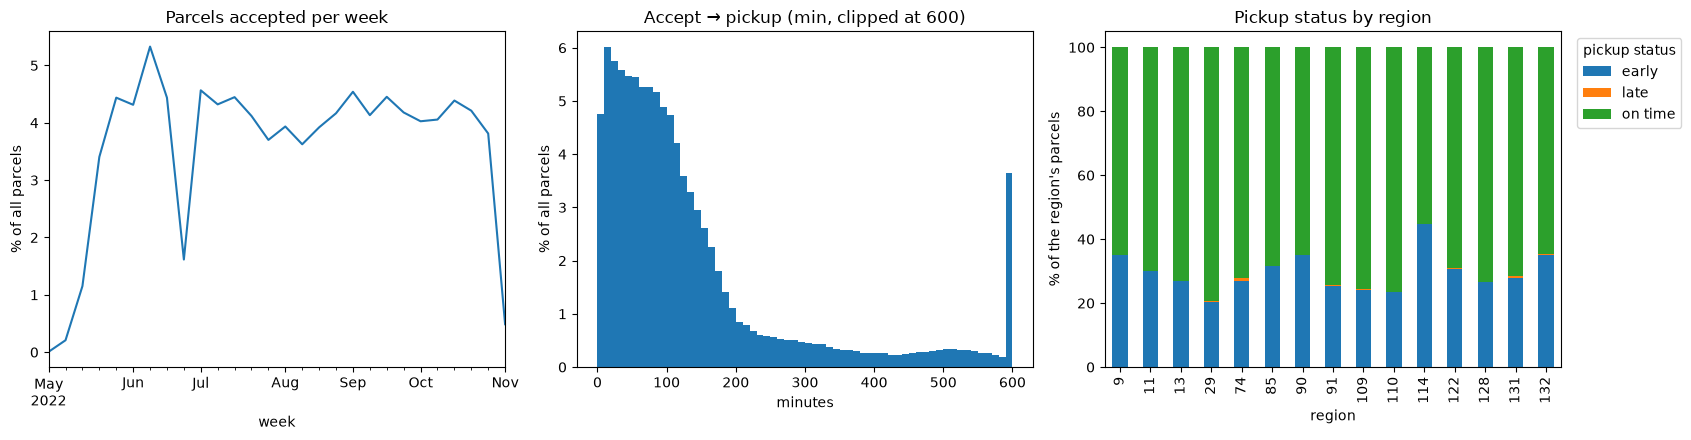

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
weekly = df.set_index("accept_time").resample("W").order_id.count()
(weekly / len(df) * 100).plot(ax=axes[0], title="Parcels accepted per week", ylabel="% of all parcels", xlabel="week")
df.accept_to_pickup_min.clip(upper=600).plot.hist(bins=60, ax=axes[1], weights=np.full(len(df), 100 / len(df)),
                                                  title="Accept → pickup (min, clipped at 600)")
axes[1].set(xlabel="minutes", ylabel="% of all parcels")
(pd.crosstab(df.region_id, df.pickup_status, normalize="index") * 100).plot.bar(
    stacked=True, ax=axes[2], title="Pickup status by region", ylabel="% of the region's parcels", xlabel="region")
axes[2].legend(title="pickup status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
fig.savefig(FIG / "01_overview.png", dpi=150, bbox_inches="tight")

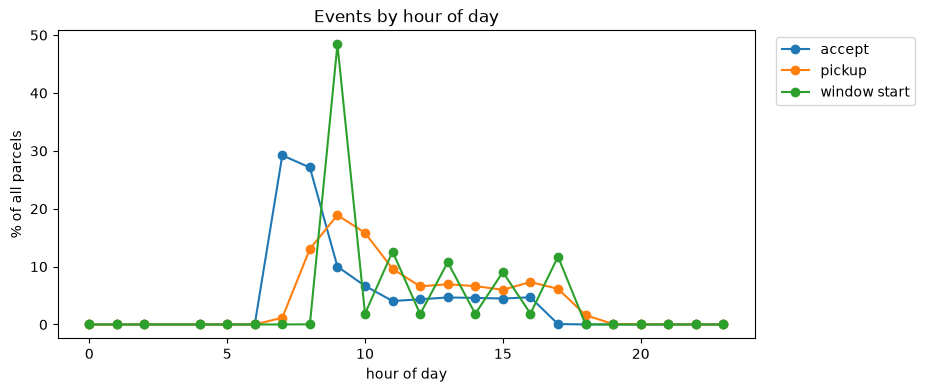

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
by_hour = pd.DataFrame({"accept": df.accept_time.dt.hour.value_counts(),
                        "pickup": df.pickup_time.dt.hour.value_counts(),
                        "window start": df.time_window_start.dt.hour.value_counts()}).sort_index().fillna(0)
(by_hour / len(df) * 100).plot(ax=ax, marker="o")
ax.set(title="Events by hour of day", xlabel="hour of day", ylabel="% of all parcels")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.savefig(FIG / "02_hour_of_day.png", dpi=150, bbox_inches="tight")

## 4. Event logs

Both logs use the same two event types per parcel: **Accept order** (`accept_time`) and **Pick up order** (`pickup_time`). `pickup_time` is used rather than `pickup_gps_time`, because the GPS time is missing for 16% of parcels.
Resource = `courier_id`. Additional attributes: region, AOI, AOI type, pickup status, minutes from accept to pickup.

In [8]:
ATTRS = ["order_id", "courier_id", "region_id", "aoi_id", "aoi_type", "ds", "pickup_status", "accept_to_pickup_min"]
events = pd.concat([
    df[ATTRS].assign(activity="Accept order", timestamp=df.accept_time),
    df[ATTRS].assign(activity="Pick up order", timestamp=df.pickup_time),
])
events["org:resource"] = events.courier_id.astype(str)
events["pickup_status"] = events.pickup_status.astype(str)
events["courier_day"] = events.courier_id.astype(str) + "_" + events.ds.astype(str).str.zfill(4)
# Accept before pick up when both share a minute
events["order"] = (events.activity == "Pick up order").astype(int)
events = events.sort_values(["timestamp", "order"]).drop(columns="order")
len(events)

523602

In [9]:
def to_log(ev, case_col):
    return pm4py.format_dataframe(ev.assign(case_id=ev[case_col].astype(str)),
                                  case_id="case_id", activity_key="activity", timestamp_key="timestamp")

log_a = to_log(events, "order_id")     # case = parcel
log_b = to_log(events, "courier_day")  # case = courier-day
print("Log A cases:", log_a["case:concept:name"].nunique(), "| Log B cases:", log_b["case:concept:name"].nunique())

Log A cases: 261801 | Log B cases: 18880


### Batching in Log B
In a courier-day, how many orders does a courier accept before the next pickup? Long runs of the same activity mean batching.

In [10]:
runs = (log_b.assign(run=(log_b["concept:name"] != log_b.groupby("case:concept:name")["concept:name"].shift()).cumsum())
        .groupby(["case:concept:name", "run", "concept:name"]).size().rename("run_length").reset_index())
runs.groupby("concept:name").run_length.describe()

,count,mean,std,min,25%,50%,75%,max
concept:name,,,,,,,,
Accept order,102338.0,2.373713,3.034606,1.0,1.0,1.0,2.0,40.0
Pick up order,108821.0,2.405795,1.939689,1.0,1.0,2.0,3.0,29.0


## 5. First discovery

In [11]:
save_dfg_percent(log_b, FIG / "03_dfg_courier_day.png", "Log B: case = courier-day", unit="courier-days")

# Log B: one variant per courier-day, so take an abstraction: collapse repeats (batch) into one event
collapsed = log_b[log_b["concept:name"] != log_b.groupby("case:concept:name")["concept:name"].shift(fill_value="")]
bpmn = pm4py.convert_to_bpmn(pm4py.discover_process_tree_inductive(collapsed, noise_threshold=0.2))
pm4py.save_vis_bpmn(bpmn, str(FIG / "04_bpmn_courier_day_collapsed.png"))
print(pm4py.get_variants(collapsed).__len__(), "variants after collapsing batches")

34 variants after collapsing batches


## 6. Export XES and basic metadata
XES files are written to `data/processed/` (not committed, they are large).

In [12]:
def basics(log, name):
    dur = pm4py.get_all_case_durations(log)
    return {
        "event log": name,
        "cases": log["case:concept:name"].nunique(),
        "events": len(log),
        "activities": log["concept:name"].nunique(),
        "variants": len(pm4py.get_variants(log)),
        "resources": log["org:resource"].nunique(),
        "mean case duration (h)": round(pd.Series(dur).mean() / 3600, 2),
        "median case duration (h)": round(pd.Series(dur).median() / 3600, 2),
        "start": log["time:timestamp"].min(),
        "end": log["time:timestamp"].max(),
    }

meta = pd.DataFrame([basics(log_a, "A: case = parcel"), basics(log_b, "B: case = courier-day")]).set_index("event log").T
meta.to_csv(ROOT / "outputs/metadata_basics.csv")
meta

event log,A: case = parcel,B: case = courier-day
cases,261801,18880
events,523602,523602
activities,2,2
variants,1,9567
resources,665,665
mean case duration (h),2.87,13.95
median case duration (h),1.53,9.33
start,2022-05-01 08:25:00+00:00,2022-05-01 08:25:00+00:00
end,2022-10-31 19:28:00+00:00,2022-10-31 19:28:00+00:00


In [13]:
pm4py.write_xes(log_a, str(PROC / "lade_jl_pickup_parcel.xes"))
pm4py.write_xes(log_b, str(PROC / "lade_jl_pickup_courier_day.xes"))
sorted((p.name, round(p.stat().st_size / 1e6, 1)) for p in PROC.iterdir())

/Users/I780299/Documents/process-mining-project/Group2_PMProject26/.venv/lib/python3.11/site-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


exporting log, completed traces ::   0%|          | 0/261801 [00:00<?, ?it/s]

exporting log, completed traces ::   0%|          | 0/18880 [00:00<?, ?it/s]

[('lade_jl_pickup_courier_day.xes', 426.1),
 ('lade_jl_pickup_parcel.xes', 441.7),
 ('lade_jl_pickup_parcel_v1.xes.gz', 27.4)]

## 7. Open questions for the consultation
- Log A has one variant (accept → pick up). Is a courier-day (Log B) or courier-level case notion acceptable, given it is closer to an object-centric view?
- Only 0.2% of pickups are after the window, but ~29% are **before** it. Should "late" for the enhancement task mean after the window, or a long accept→pickup time?
- Can we combine LaDe-P with LaDe-D (pickup and delivery), or stay with pickup only?
- Is it fine to keep Jilin as the main log and use the other cities only for comparison?
- Should we add GPS-based events (e.g., courier arrival at AOI) from the trajectory data?